In this notebook I will compute the different contributions to P3D (Lya, HCD, LyaHCD) and compare with cupix (using same cosmology and vega's column density distribution function)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import h5py
from cupix.likelihood.theory import Theory
from scipy.interpolate import RegularGridInterpolator

import sys
import os
sys.path.append(os.path.abspath(".."))
from model import p3d_model, p1d_model
from utils import Cosmologies

# Model

In [2]:
# MW11 cosmology, for example
cosmo = Cosmologies().get_cosmo(name='MW11')  # For example
bias_hcd, bias_lya = 2, -0.19
z = 2.5

In [3]:
fn_file = '/data/desi/scratch/lfloresl/astrid_hcd_outputs/fn_pyigm/fn_pyigm1'

with h5py.File(fn_file, 'r') as f:
    print('Atributes:')
    for m in f.attrs.keys():
        print(f'{m} = {f.attrs[m]}')
    logNHI_max = f.attrs['logNHI_max']
    logNHI_min = f.attrs['logNHI_min']
    print('----------------') 
    print('Data:')
    print(f.keys())

    NHirange = np.linspace(logNHI_min, logNHI_max) 
    logfNHiX = np.interp(NHirange, f['logNhi'][:], f['fn'][:][:, 0])
    fNHiX = 10**(logfNHiX)

Atributes:
Redshift = 2.5
logNHI_max = 21.3
logNHI_min = 17.2
----------------
Data:
<KeysViewHDF5 ['fn', 'logNhi']>


In [4]:
results_3d = p3d_model(bias_hcd, bias_lya, z, cosmo, NHirange, fNHiX, Mpc=True)
k = results_3d['k']
mu = results_3d['mu']
p3d_tot = results_3d['p3d_tot']
p3d_lya = results_3d['p3d_lya']
p3d_hcd = results_3d['p3d_hcd']
p3d_lyahcd = results_3d['p3d_lyahcd']

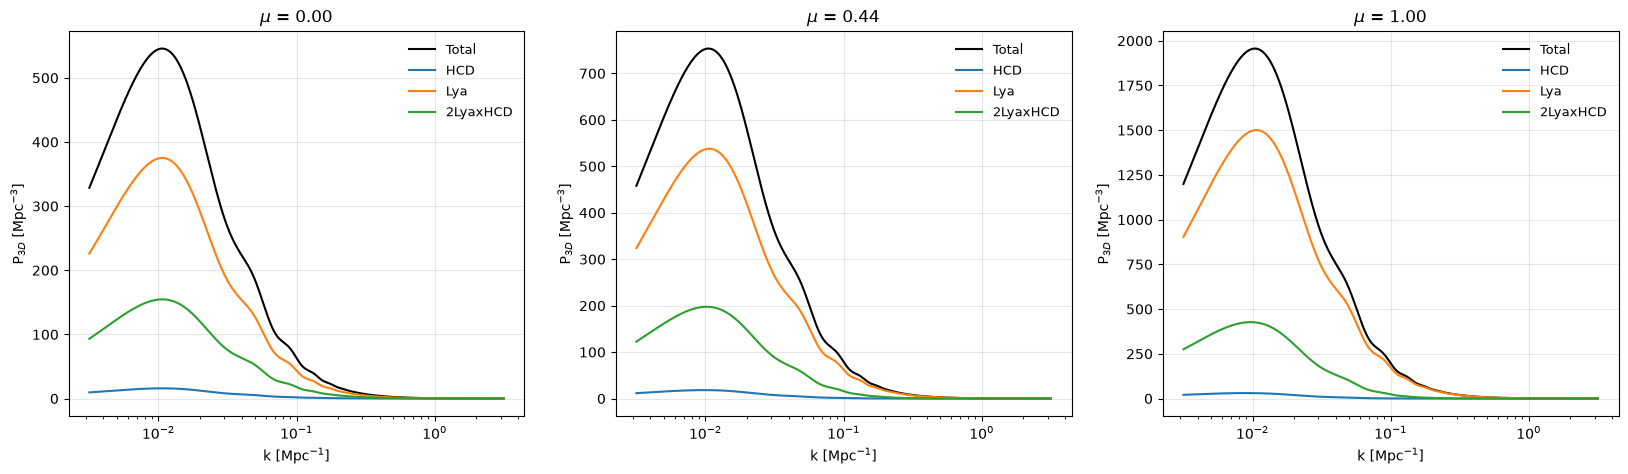

In [5]:
plt.figure(figsize=(20, 5))

plt.subplot(1, 3, 1)
i = 0
plt.plot(k, p3d_tot[i], color='k', label='Total')
plt.plot(k, p3d_hcd[i], label='HCD')
plt.plot(k, p3d_lya[i], label='Lya')
plt.plot(k, 2*p3d_lyahcd[i], label='2LyaxHCD')

plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}$ [Mpc$^{-3}$]')
plt.title(r'$\mu$ = %.2f' %mu[i])

plt.subplot(1, 3, 2)
i = 4
plt.plot(k, p3d_tot[i], color='k', label='Total')
plt.plot(k, p3d_hcd[i], label='HCD')
plt.plot(k, p3d_lya[i], label='Lya')
plt.plot(k, 2*p3d_lyahcd[i], label='2LyaxHCD')
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}$ [Mpc$^{-3}$]')
plt.title(r'$\mu$ = %.2f' %mu[i])

plt.subplot(1, 3, 3)
i = 9
plt.plot(k, p3d_tot[i], color='k', label='Total')
plt.plot(k, p3d_hcd[i], label='HCD')
plt.plot(k, p3d_lya[i], label='Lya')
plt.plot(k, 2*p3d_lyahcd[i], label='2LyaxHCD')
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}$ [Mpc$^{-3}$]')
plt.title(r'$\mu$ = %.2f' %mu[i]);

# Cupix (linear)

In [6]:
# lya bias / beta from that paper
bias = -bias_lya
beta = 1
# close to value used in McQuinn & White, although in there this is kpar smoothing only
kp_Mpc = 0.08 * cosmo.get_dkms_dMpc(z)
print('k_p = {:.3f} 1/Mpc'.format(kp_Mpc))
# HCD model (L_H
b_H = results_3d['bias_hcd_flux']
beta_H = 0.5
L_H = 7.0  * cosmo.get_h()
print('L_H = {:.3f} Mpc'.format(L_H))
config = dict(bias=bias, beta=beta, q1=0, q2=0, kp_Mpc=kp_Mpc,
              include_hcd=True, b_H=b_H, beta_H=beta_H, L_H=L_H,
              verbose=True)

k_p = 5.708 1/Mpc
L_H = 4.970 Mpc


In [7]:
theory = Theory(z, fid_cosmo=cosmo, config=config)

LyaModel::setup_from_config
LyaModel::get_default_lya_params
initial values {'bias': np.float64(-0.13827178966115714), 'beta': np.float64(1.4178048358716402), 'q1': np.float64(0.33369611625260176), 'kvav': np.float64(0.5709771352811059), 'av': np.float64(0.4055657283063022), 'bv': np.float64(1.6647876909430759), 'kp': np.float64(12.514370161342079), 'q2': np.float64(0.2533086488252884)}
final values {'bias': 0.19, 'beta': 1, 'q1': 0, 'av': np.float64(0.4055657283063022), 'bv': np.float64(1.6647876909430759), 'q2': 0, 'kp_Mpc': 5.707875454974727, 'kv_Mpc': np.float64(0.25112897347553936)}
ContaminantsModel::setup_from_config


In [8]:
lya_params = theory.lya_model.get_lya_params(cosmo, params={})
plin = cosmo.get_linP_Mpc(z, k)
nonlin = []
p3d_lya_cupix, p3d_total_cupix = [], []
for mu_value in mu:
    p3d_total_cupix.append(theory.get_p3d_lya_hcd_Mpc(k, mu_value))
    p3d_lya_cupix.append(theory.get_p3d_lya_Mpc(k, mu_value))
    nonlin.append(theory._compute_DNL_Arinyo(k, mu_value, plin, lya_params))
p3d_total_cupix, p3d_lya_cupix = np.array(p3d_total_cupix), np.array(p3d_lya_cupix)
nonlin = np.array(nonlin)

recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function


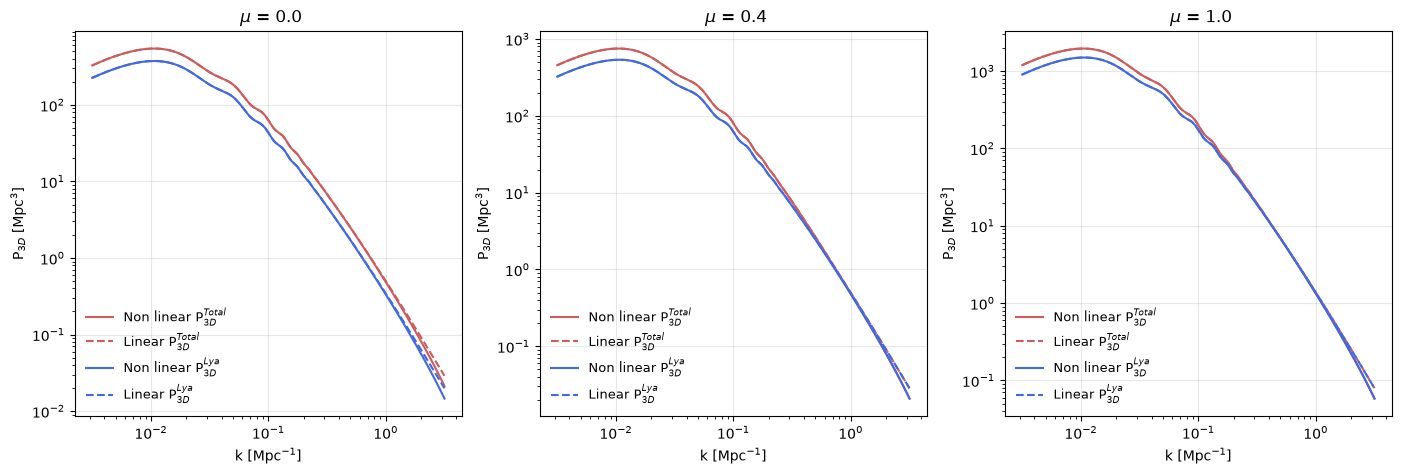

In [9]:
plt.figure(figsize=(17, 5))

plt.subplot(1, 3, 1)
i = 0
plt.plot(k, p3d_total_cupix[i, :], color='indianred', label=r'Non linear P$_{3D}^{Total}$')
plt.plot(k, p3d_total_cupix[i, :]/nonlin[i, :], color='indianred', linestyle='--', label=r'Linear P$_{3D}^{Total}$')
plt.plot(k, p3d_lya_cupix[i, :], color='royalblue', label=r'Non linear P$_{3D}^{Lya}$')
plt.plot(k, p3d_lya_cupix[i, :]/nonlin[i, :], color='royalblue', linestyle='--', label=r'Linear P$_{3D}^{Lya}$')
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False, loc='lower left')
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}$ [Mpc$^3$]')
plt.title(r' $\mu$ = %.01f' %mu[i]);

plt.subplot(1, 3, 2)
i = 4
plt.plot(k, p3d_total_cupix[i, :], color='indianred', label=r'Non linear P$_{3D}^{Total}$')
plt.plot(k, p3d_total_cupix[i, :]/nonlin[i, :], color='indianred', linestyle='--', label=r'Linear P$_{3D}^{Total}$')
plt.plot(k, p3d_lya_cupix[i, :], color='royalblue', label=r'Non linear P$_{3D}^{Lya}$')
plt.plot(k, p3d_lya_cupix[i, :]/nonlin[i, :], color='royalblue', linestyle='--', label=r'Linear P$_{3D}^{Lya}$')
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False, loc='lower left')
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}$ [Mpc$^3$]')
plt.title(r' $\mu$ = %.01f' %mu[i]);

plt.subplot(1, 3, 3)
i = 9
plt.plot(k, p3d_total_cupix[i, :], color='indianred', label=r'Non linear P$_{3D}^{Total}$')
plt.plot(k, p3d_total_cupix[i, :]/nonlin[i, :], color='indianred', linestyle='--', label=r'Linear P$_{3D}^{Total}$')
plt.plot(k, p3d_lya_cupix[i, :], color='royalblue', label=r'Non linear P$_{3D}^{Lya}$')
plt.plot(k, p3d_lya_cupix[i, :]/nonlin[i, :], color='royalblue', linestyle='--', label=r'Linear P$_{3D}^{Lya}$')
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False, loc='lower left')
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}$ [Mpc$^3$]')
plt.title(r' $\mu$ = %.01f' %mu[i]);

If we want to check the effect of the exponential part (k smoothing) included in the MW11 lya model:

In [10]:
results_1d = p1d_model(bias_hcd, bias_lya, z, cosmo, NHirange, fNHiX)
k_los = results_1d['k_los']

In [11]:
dkms_dMpc = cosmo.get_dkms_dMpc(z)
k_d = 0.08*dkms_dMpc
exp = np.exp(-(k_los**2/k_d**2))

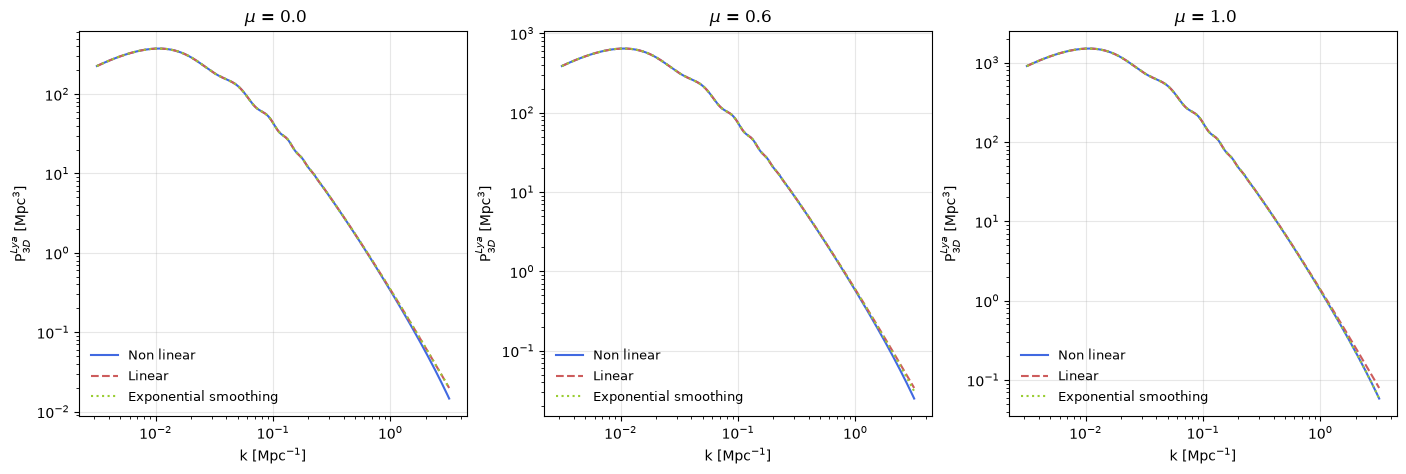

In [12]:
plt.figure(figsize=(17, 5))

plt.subplot(1, 3, 1)
i = 0
plt.plot(k, p3d_lya_cupix[i, :], color='royalblue', label=r'Non linear')
plt.plot(k, p3d_lya_cupix[i, :]/nonlin[i, :], color='indianred', linestyle='--', label=r'Linear')
plt.plot(k, p3d_lya[i, :], color='yellowgreen', linestyle=':', label='Exponential smoothing')
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False, loc='lower left')
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Lya}$ [Mpc$^3$]')
plt.title(r' $\mu$ = %.01f' %mu[i]);

plt.subplot(1, 3, 2)
i = 5
plt.plot(k, p3d_lya_cupix[i, :], color='royalblue', label=r'Non linear')
plt.plot(k, p3d_lya_cupix[i, :]/nonlin[i, :], color='indianred', linestyle='--', label=r'Linear')
plt.plot(k, p3d_lya[i, :], color='yellowgreen', linestyle=':', label='Exponential smoothing')
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False, loc='lower left')
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Lya}$ [Mpc$^3$]')
plt.title(r' $\mu$ = %.01f' %mu[i]);

plt.subplot(1, 3, 3)
i = 9
plt.plot(k, p3d_lya_cupix[i, :], color='royalblue', label=r'Non linear')
plt.plot(k, p3d_lya_cupix[i, :]/nonlin[i, :], color='indianred', linestyle='--', label=r'Linear')
plt.plot(k, p3d_lya[i, :], color='yellowgreen', linestyle=':', label='Exponential smoothing')
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False, loc='lower left')
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Lya}$ [Mpc$^3$]')
plt.title(r' $\mu$ = %.01f' %mu[i]);

There is barely any differences

# Comparisons

## Total

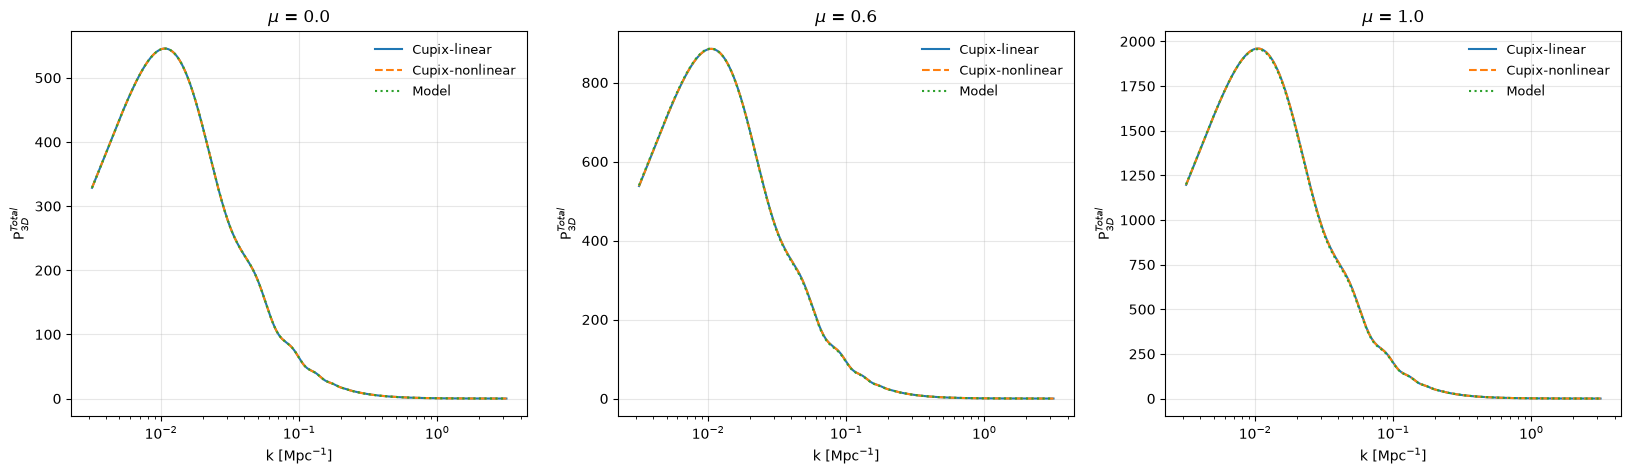

In [36]:
plt.figure(figsize=(20, 5))

plt.subplot(1, 3, 1)
i = 0
plt.plot(k, p3d_total_cupix[i]/nonlin[i], label='Cupix-linear')
plt.plot(k, p3d_total_cupix[i], linestyle='--', label='Cupix-nonlinear')
plt.plot(k, p3d_tot[i], linestyle=':', label='Model')
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Total}$')
plt.title(r'$\mu$ = %.1f' %mu[i]);

plt.subplot(1, 3, 2)
i = 5
plt.plot(k, p3d_total_cupix[i]/nonlin[i], label='Cupix-linear')
plt.plot(k, p3d_total_cupix[i], linestyle='--', label='Cupix-nonlinear')
plt.plot(k, p3d_tot[i], linestyle=':', label='Model')
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Total}$')
plt.title(r'$\mu$ = %.1f' %mu[i]);

plt.subplot(1, 3, 3)
i = 9
plt.plot(k, p3d_total_cupix[i]/nonlin[i], label='Cupix-linear')
plt.plot(k, p3d_total_cupix[i], linestyle='--', label='Cupix-nonlinear')
plt.plot(k, p3d_tot[i], linestyle=':', label='Model')
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Total}$')
plt.title(r'$\mu$ = %.1f' %mu[i]);

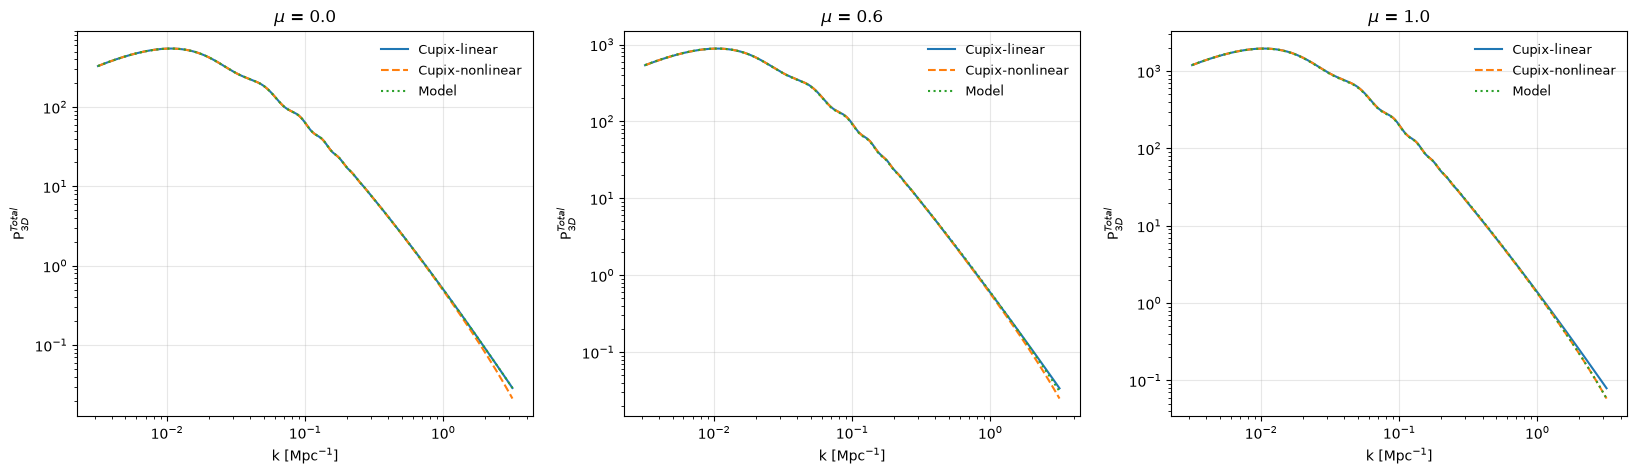

In [37]:
plt.figure(figsize=(20, 5))

plt.subplot(1, 3, 1)
i = 0
plt.plot(k, p3d_total_cupix[i]/nonlin[i], label='Cupix-linear')
plt.plot(k, p3d_total_cupix[i], linestyle='--', label='Cupix-nonlinear')
plt.plot(k, p3d_tot[i], linestyle=':', label='Model')
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Total}$')
plt.title(r'$\mu$ = %.1f' %mu[i]);

plt.subplot(1, 3, 2)
i = 5
plt.plot(k, p3d_total_cupix[i]/nonlin[i], label='Cupix-linear')
plt.plot(k, p3d_total_cupix[i], linestyle='--', label='Cupix-nonlinear')
plt.plot(k, p3d_tot[i], linestyle=':', label='Model')
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Total}$')
plt.title(r'$\mu$ = %.1f' %mu[i]);

plt.subplot(1, 3, 3)
i = 9
plt.plot(k, p3d_total_cupix[i]/nonlin[i], label='Cupix-linear')
plt.plot(k, p3d_total_cupix[i], linestyle='--', label='Cupix-nonlinear')
plt.plot(k, p3d_tot[i], linestyle=':', label='Model')
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Total}$')
plt.title(r'$\mu$ = %.1f' %mu[i]);

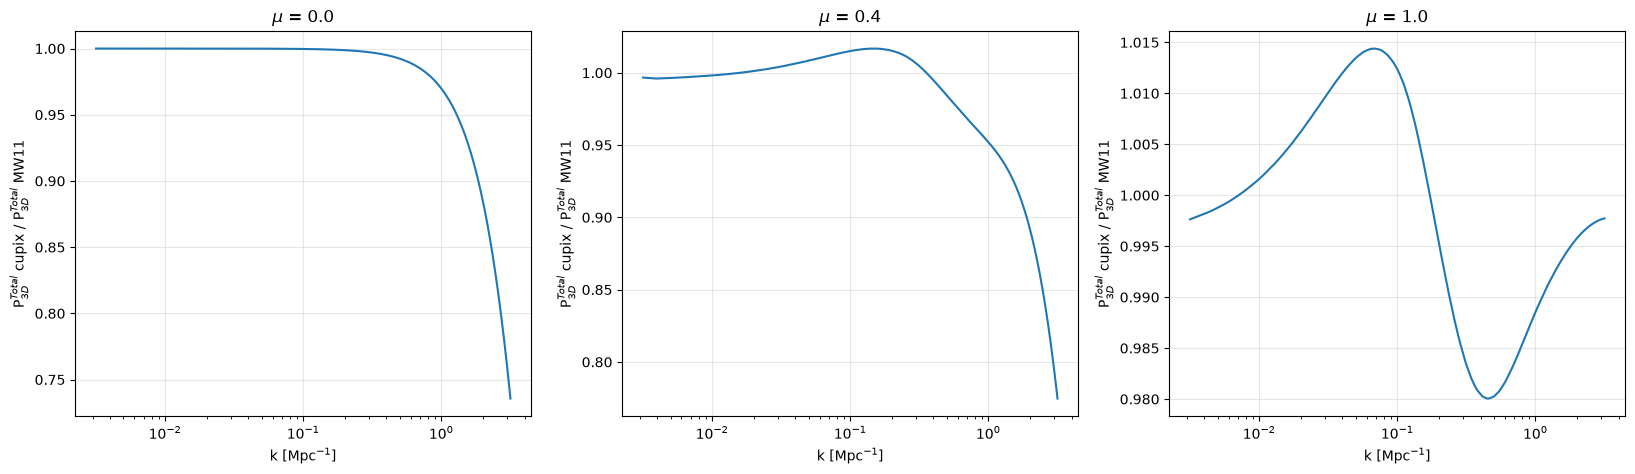

In [14]:
plt.figure(figsize=(20, 5))

plt.subplot(1, 3, 1)
i = 0
plt.plot(k, p3d_total_cupix[i]/p3d_tot[i])
plt.xscale('log')
plt.grid(alpha=0.3)
#plt.ylim(0.7, 1.4)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Total}$ cupix / P$_{3D}^{Total}$ MW11')
plt.title(r'$\mu$ = %.1f' %mu[i]);

plt.subplot(1, 3, 2)
i = 4
plt.plot(k, p3d_total_cupix[i]/p3d_tot[i])
plt.xscale('log')
plt.grid(alpha=0.3)
#plt.ylim(0.7, 1.4)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Total}$ cupix / P$_{3D}^{Total}$ MW11')
plt.title(r'$\mu$ = %.1f' %mu[i]);

plt.subplot(1, 3, 3)
i = 9
plt.plot(k, p3d_total_cupix[i]/p3d_tot[i])
plt.xscale('log')
plt.grid(alpha=0.3)
#plt.ylim(1.4, 0.7)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Total}$ cupix / P$_{3D}^{Total}$ MW11')
plt.title(r'$\mu$ = %.1f' %mu[i]);

## Lya only

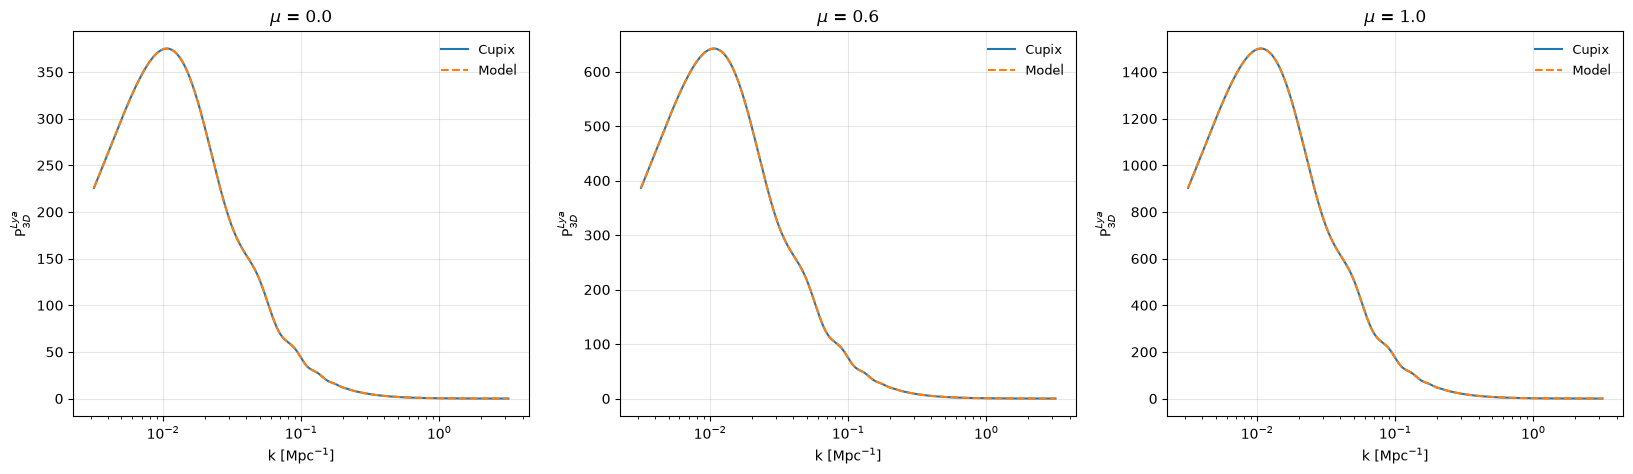

In [15]:
plt.figure(figsize=(20, 5))

plt.subplot(1, 3, 1)
i = 0
plt.plot(k, p3d_lya_cupix[i], label='Cupix')
plt.plot(k, p3d_lya[i], linestyle='--', label='Model')
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Lya}$')
plt.title(r'$\mu$ = %.1f' %mu[i]);

plt.subplot(1, 3, 2)
i = 5
plt.plot(k, p3d_lya_cupix[i], label='Cupix')
plt.plot(k, p3d_lya[i], linestyle='--', label='Model')
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Lya}$')
plt.title(r'$\mu$ = %.1f' %mu[i]);

plt.subplot(1, 3, 3)
i = 9
plt.plot(k, p3d_lya_cupix[i], label='Cupix')
plt.plot(k, p3d_lya[i], linestyle='--', label='Model')
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{Lya}$')
plt.title(r'$\mu$ = %.1f' %mu[i]);

## Lya x HCD

In [23]:
p3d_cross_cupix_lin = (p3d_total_cupix - p3d_lya_cupix - p3d_hcd_cupix)/2

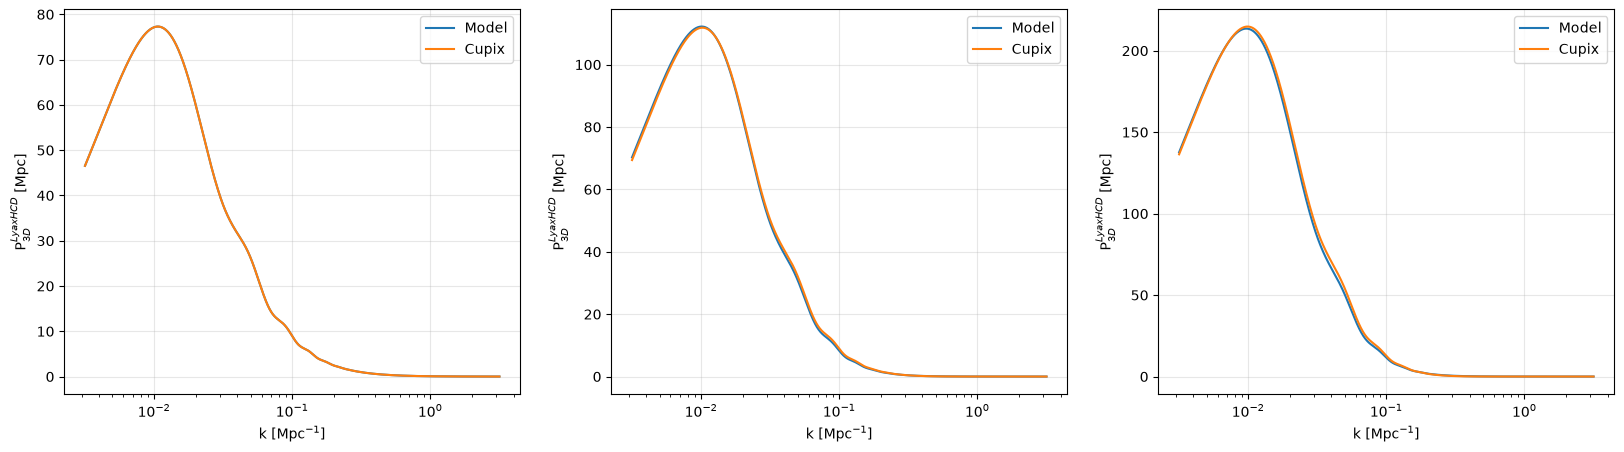

In [24]:
plt.figure(figsize=(20, 5))

plt.subplot(1, 3, 1)
i = 0
plt.plot(k, p3d_lyahcd[i], label='Model')
plt.plot(k, p3d_cross_cupix_lin[i], label='Cupix')
plt.xscale('log')
plt.legend()
plt.grid(alpha=0.3)
plt.xlabel('k [Mpc$^{-1}$]')
plt.ylabel('P$_{3D}^{LyaxHCD}$ [Mpc]')

plt.subplot(1, 3, 2)
i = 5
plt.plot(k, p3d_lyahcd[i], label='Model')
plt.plot(k, p3d_cross_cupix_lin[i], label='Cupix')
plt.xscale('log')
plt.legend()
plt.grid(alpha=0.3)
plt.xlabel('k [Mpc$^{-1}$]')
plt.ylabel('P$_{3D}^{LyaxHCD}$ [Mpc]')

plt.subplot(1, 3, 3)
i = 9
plt.plot(k, p3d_lyahcd[i], label='Model')
plt.plot(k, p3d_cross_cupix_lin[i], label='Cupix')
plt.xscale('log')
plt.legend()
plt.grid(alpha=0.3)
plt.xlabel('k [Mpc$^{-1}$]')
plt.ylabel('P$_{3D}^{LyaxHCD}$ [Mpc]');

## HCD only

In [25]:
# lya bias / beta from that paper
bias = 0
beta = 1
# close to value used in McQuinn & White, although in there this is kpar smoothing only
kp_Mpc = 0.08 * cosmo.get_dkms_dMpc(z)
print('k_p = {:.3f} 1/Mpc'.format(kp_Mpc))
# HCD model (L_H
b_H = results_3d['bias_hcd_flux']
beta_H = 0.5
L_H = 7.0  * cosmo.get_h()
print('L_H = {:.3f} Mpc'.format(L_H))
config = dict(bias=bias, beta=beta, q1=0, q2=0, kp_Mpc=kp_Mpc,
              include_hcd=True, b_H=b_H, beta_H=beta_H, L_H=L_H,
              verbose=True)

k_p = 5.708 1/Mpc
L_H = 4.970 Mpc


In [26]:
theory = Theory(z, fid_cosmo=cosmo, config=config)

LyaModel::setup_from_config
LyaModel::get_default_lya_params
initial values {'bias': np.float64(-0.13827178966115714), 'beta': np.float64(1.4178048358716402), 'q1': np.float64(0.33369611625260176), 'kvav': np.float64(0.5709771352811059), 'av': np.float64(0.4055657283063022), 'bv': np.float64(1.6647876909430759), 'kp': np.float64(12.514370161342079), 'q2': np.float64(0.2533086488252884)}
final values {'bias': 0, 'beta': 1, 'q1': 0, 'av': np.float64(0.4055657283063022), 'bv': np.float64(1.6647876909430759), 'q2': 0, 'kp_Mpc': 5.707875454974727, 'kv_Mpc': np.float64(0.25112897347553936)}
ContaminantsModel::setup_from_config


In [27]:
lya_params = theory.lya_model.get_lya_params(cosmo, params={})
plin = cosmo.get_linP_Mpc(z, k)
nonlin = []
p3d_hcd_cupix = []
for mu_value in mu:
    p3d_hcd_cupix.append(theory.get_p3d_lya_hcd_Mpc(k, mu_value))
    nonlin.append(theory._compute_DNL_Arinyo(k, mu_value, plin, lya_params))
p3d_hcd_cupix = np.array(p3d_hcd_cupix)
nonlin = np.array(nonlin)
p3d_hcd_cupix_lin = p3d_hcd_cupix/nonlin

recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function


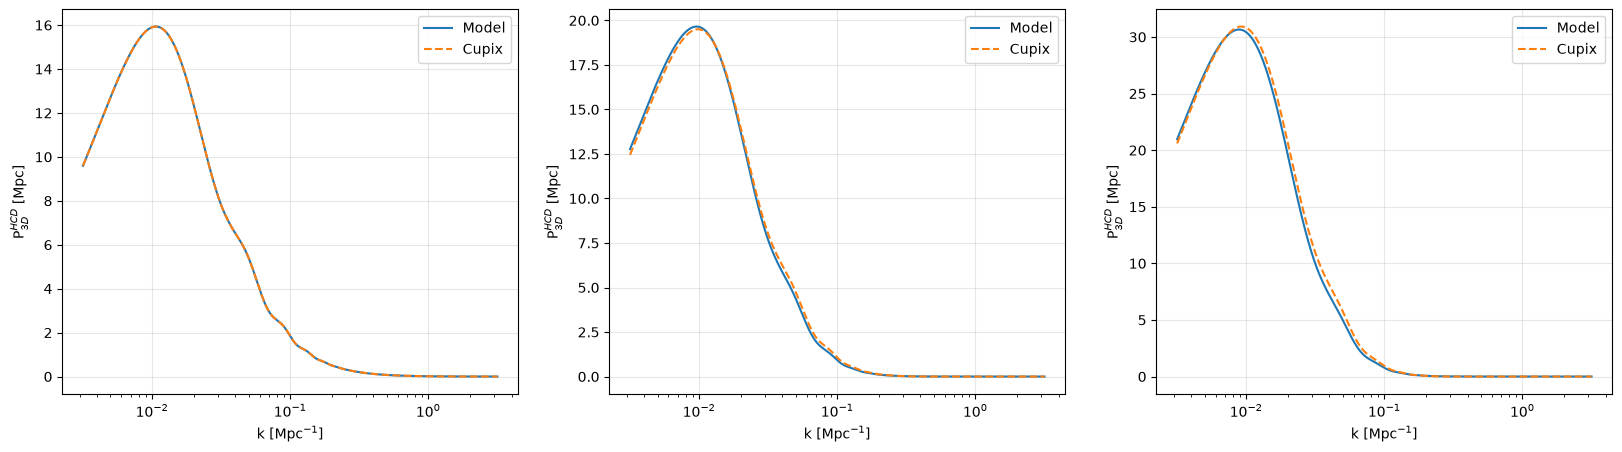

In [28]:
plt.figure(figsize=(20, 5))

plt.subplot(1, 3, 1)
i = 0
plt.plot(k, p3d_hcd[i], label='Model')
plt.plot(k, p3d_hcd_cupix_lin[i], linestyle='--', label='Cupix')
plt.xscale('log')
plt.legend()
plt.grid(alpha=0.3)
plt.xlabel('k [Mpc$^{-1}$]')
plt.ylabel('P$_{3D}^{HCD}$ [Mpc]')

plt.subplot(1, 3, 2)
i = 5
plt.plot(k, p3d_hcd[i], label='Model')
plt.plot(k, p3d_hcd_cupix_lin[i], linestyle='--', label='Cupix')
plt.xscale('log')
plt.legend()
plt.grid(alpha=0.3)
plt.xlabel('k [Mpc$^{-1}$]')
plt.ylabel('P$_{3D}^{HCD}$ [Mpc]')

plt.subplot(1, 3, 3)
i = 9
plt.plot(k, p3d_hcd[i], label='Model')
plt.plot(k, p3d_hcd_cupix_lin[i], linestyle='--', label='Cupix')
plt.xscale('log')
plt.legend()
plt.grid(alpha=0.3)
plt.xlabel('k [Mpc$^{-1}$]')
plt.ylabel('P$_{3D}^{HCD}$ [Mpc]');

So the problem comes from the HCD contribution (HCD only and LyaxHCD)

## Where is the problem coming from

In [30]:
# lya bias / beta from that paper
bias = -bias_lya
beta = 1
# close to value used in McQuinn & White, although in there this is kpar smoothing only
kp_Mpc = 0.08 * cosmo.get_dkms_dMpc(z)
print('k_p = {:.3f} 1/Mpc'.format(kp_Mpc))
# HCD model (L_H
b_H = results_3d['bias_hcd_flux']
beta_H = 0.5
L_H = 7.0  * cosmo.get_h()
print('L_H = {:.3f} Mpc'.format(L_H))
config = dict(bias=bias, beta=beta, q1=0, q2=0, kp_Mpc=kp_Mpc,
              include_hcd=True, b_H=b_H, beta_H=beta_H, L_H=L_H,
              verbose=True)

k_p = 5.708 1/Mpc
L_H = 4.970 Mpc


In [31]:
theory = Theory(z, fid_cosmo=cosmo, config=config)

LyaModel::setup_from_config
LyaModel::get_default_lya_params
initial values {'bias': np.float64(-0.13827178966115714), 'beta': np.float64(1.4178048358716402), 'q1': np.float64(0.33369611625260176), 'kvav': np.float64(0.5709771352811059), 'av': np.float64(0.4055657283063022), 'bv': np.float64(1.6647876909430759), 'kp': np.float64(12.514370161342079), 'q2': np.float64(0.2533086488252884)}
final values {'bias': 0.19, 'beta': 1, 'q1': 0, 'av': np.float64(0.4055657283063022), 'bv': np.float64(1.6647876909430759), 'q2': 0, 'kp_Mpc': 5.707875454974727, 'kv_Mpc': np.float64(0.25112897347553936)}
ContaminantsModel::setup_from_config


In [32]:
lya_params = theory.lya_model.get_lya_params(cosmo, params={})
plin = cosmo.get_linP_Mpc(z, k)
nonlin = []
p3d_lya_cupix, p3d_total_cupix = [], []
for mu_value in mu:
    p3d_total_cupix.append(theory.get_p3d_lya_hcd_Mpc(k, mu_value))
    p3d_lya_cupix.append(theory.get_p3d_lya_Mpc(k, mu_value))
    nonlin.append(theory._compute_DNL_Arinyo(k, mu_value, plin, lya_params))
p3d_total_cupix, p3d_lya_cupix = np.array(p3d_total_cupix), np.array(p3d_lya_cupix)
nonlin = np.array(nonlin)

recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function
recycle transfer function


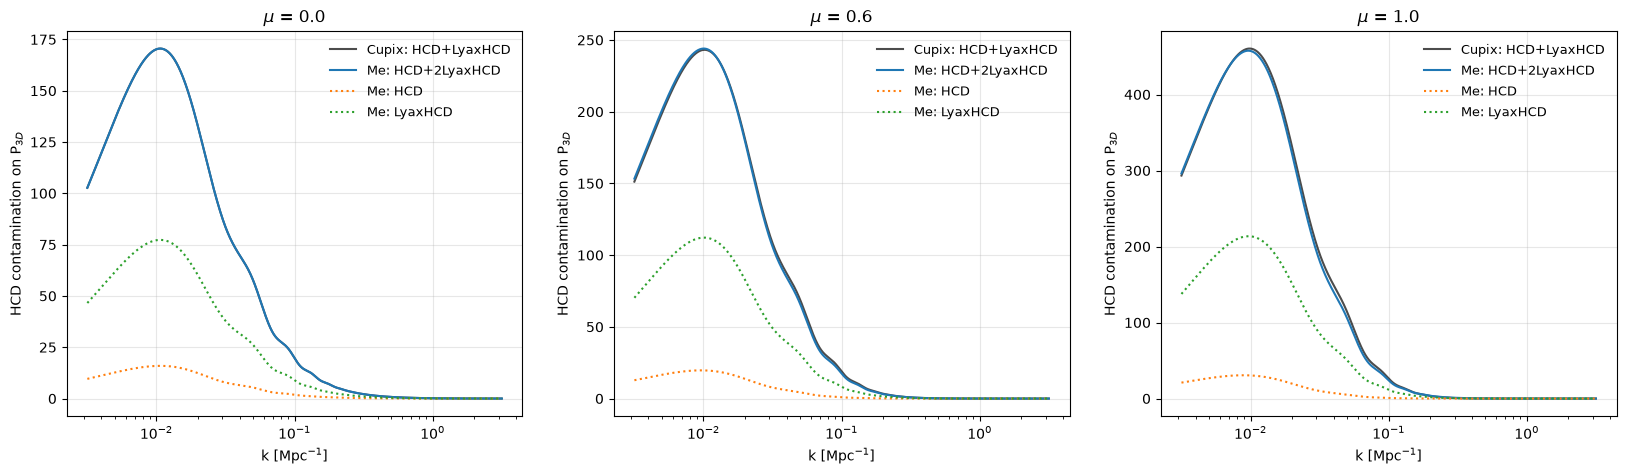

In [33]:
plt.figure(figsize=(20, 5))

plt.subplot(1, 3, 1)
i = 0
plt.plot(k, (p3d_total_cupix[i]-p3d_lya_cupix[i]), color='k', alpha=0.7, label='Cupix: HCD+LyaxHCD')
plt.plot(k, p3d_hcd[i] + 2*p3d_lyahcd[i], label='Me: HCD+2LyaxHCD')
plt.plot(k, p3d_hcd[i], linestyle=':', label='Me: HCD')
plt.plot(k, p3d_lyahcd[i], linestyle=':', label='Me: LyaxHCD')
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'HCD contamination on P$_{3D}$')
plt.title(r'$\mu$ = %.1f' %mu[i]);

plt.subplot(1, 3, 2)
i = 5
plt.plot(k, (p3d_total_cupix[i]-p3d_lya_cupix[i]), color='k', alpha=0.7, label='Cupix: HCD+LyaxHCD')
plt.plot(k, p3d_hcd[i] + 2*p3d_lyahcd[i], label='Me: HCD+2LyaxHCD')
plt.plot(k, p3d_hcd[i], linestyle=':', label='Me: HCD')
plt.plot(k, p3d_lyahcd[i], linestyle=':', label='Me: LyaxHCD')
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'HCD contamination on P$_{3D}$')
plt.title(r'$\mu$ = %.1f' %mu[i]);

plt.subplot(1, 3, 3)
i = 9
plt.plot(k, (p3d_total_cupix[i]-p3d_lya_cupix[i]), color='k', alpha=0.7, label='Cupix: HCD+LyaxHCD')
plt.plot(k, p3d_hcd[i] + 2*p3d_lyahcd[i], label='Me: HCD+2LyaxHCD')
plt.plot(k, p3d_hcd[i], linestyle=':', label='Me: HCD')
plt.plot(k, p3d_lyahcd[i], linestyle=':', label='Me: LyaxHCD')
plt.xscale('log')
plt.grid(alpha=0.3)
plt.legend(fontsize=9.5, frameon=False)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'HCD contamination on P$_{3D}$')
plt.title(r'$\mu$ = %.1f' %mu[i]);

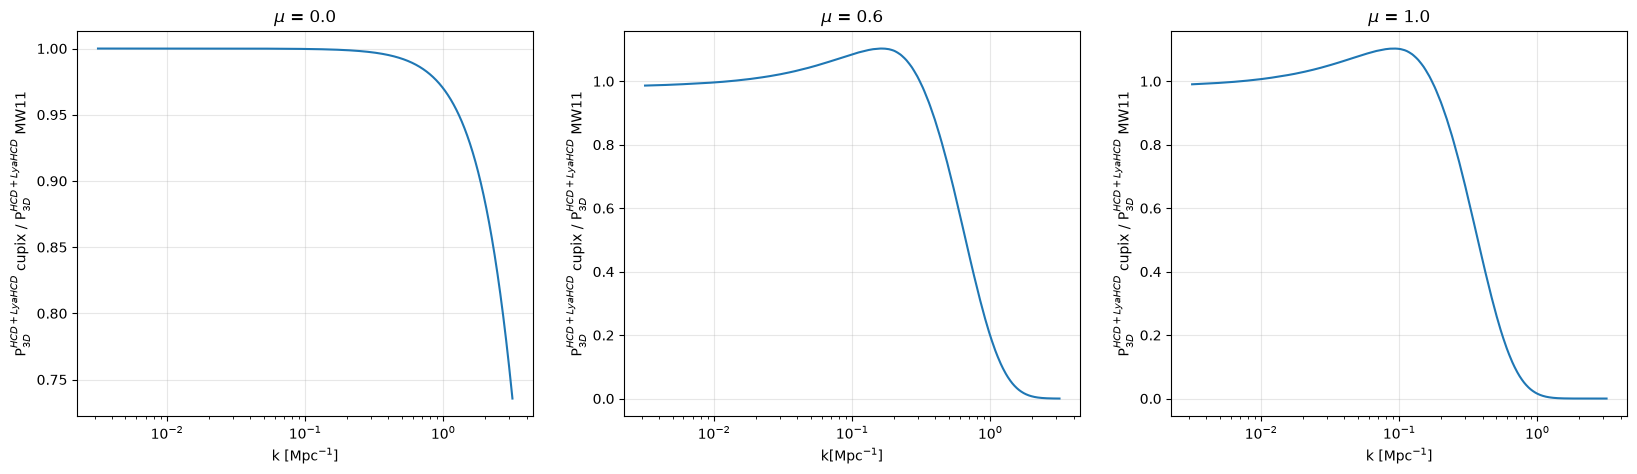

In [35]:
plt.figure(figsize=(20, 5))

plt.subplot(1, 3, 1)
i = 0
plt.plot(k, (p3d_total_cupix[i]-p3d_lya_cupix[i])/(p3d_hcd[i] + 2*p3d_lyahcd[i]))
plt.xscale('log')
plt.grid(alpha=0.3)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{HCD+LyaHCD}$ cupix / P$_{3D}^{HCD+LyaHCD}$ MW11')
plt.title(r'$\mu$ = %.1f' %mu[i]);

plt.subplot(1, 3, 2)
i = 5
plt.plot(k, (p3d_total_cupix[i]-p3d_lya_cupix[i])/(p3d_hcd[i] + 2*p3d_lyahcd[i]))
plt.xscale('log')
plt.grid(alpha=0.3)
plt.xlabel(r'k[Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{HCD+LyaHCD}$ cupix / P$_{3D}^{HCD+LyaHCD}$ MW11')
plt.title(r'$\mu$ = %.1f' %mu[i]);

plt.subplot(1, 3, 3)
i = 9
plt.plot(k, (p3d_total_cupix[i]-p3d_lya_cupix[i])/(p3d_hcd[i] + 2*p3d_lyahcd[i]))
plt.xscale('log')
plt.grid(alpha=0.3)
plt.xlabel(r'k [Mpc$^{-1}$]')
plt.ylabel(r'P$_{3D}^{HCD+LyaHCD}$ cupix / P$_{3D}^{HCD+LyaHCD}$ MW11')
plt.title(r'$\mu$ = %.1f' %mu[i]);